In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

# Question 1: Identify Data Quality Issues 

1. Load the Titanic dataset using Pandas. 

In [3]:
df=pd.read_csv(r"C:\Users\Mozassam Imam\Desktop\AI\CampusX\ML\19_Understanding_data\train_titanic.csv")

2. Display the first 10 and last 5 records. 

In [4]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [5]:
df.tail(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


3. Display the dataset shape, column names, and data types

In [6]:
df.shape

(891, 12)

In [7]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [11]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

4. Identify and display column-wise missing values. 


In [12]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

5. Check and report duplicate records.

In [14]:
df.duplicated().sum()

0

No duplicate record present

# Question 2: Handle Missing Values & Duplicates 

1. Handle missing values in Age using mean or median imputation. 

In [15]:
df['Age'] = df['Age'].fillna(df['Age'].mean())

In [16]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

No missing values in age this tells that the value of age is now filled with mean 

In [19]:
df['Age'].isnull().sum()

0

In [20]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


2. Handle missing values in Embarked using the mode. 

In [21]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [22]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [24]:
df['Embarked'].isnull().sum()

0

No missing vlaue in embarked

3. Remove duplicate records, if any. 

In [25]:
df = df.drop_duplicates()

In [28]:
df.duplicated().sum()

0

4. Calculate:
• Average age of passengers.
• Average fare.
• Number of survivors and non-survivors. 

In [29]:
average_age = df['Age'].mean()
print("Average Age:", average_age)

Average Age: 29.69911764705882


In [30]:
average_fare = df['Fare'].mean()
print("Average Fare:", average_fare)

Average Fare: 32.204207968574636


In [31]:
survivors = (df['Survived'] == 1).sum()
non_survivors = (df['Survived'] == 0).sum()

print("Number of Survivors:", survivors)
print("Number of Non-Survivors:", non_survivors)

Number of Survivors: 342
Number of Non-Survivors: 549


5. Find the survival rate for male and female passengers.

In [37]:
survival_rate=df.groupby('Sex')['Survived'].mean()*100

In [38]:
survival_rate

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

# Question 3: Univariate EDA

1. Plot a histogram of passenger ages. 

Text(0, 0.5, 'People')

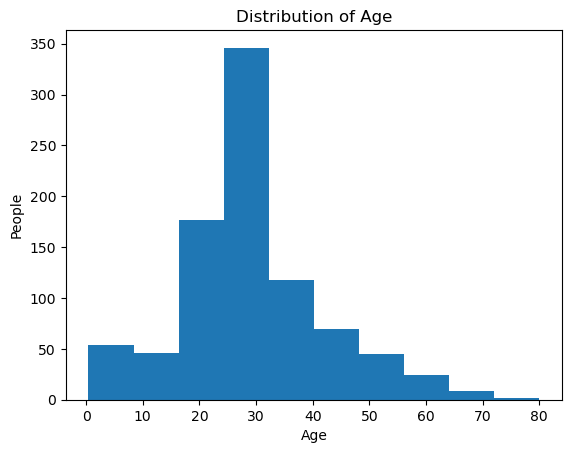

In [41]:
plt.hist(df['Age'])
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("People")

2. Create a bar chart showing survivors vs. non-survivors. 

Text(0, 0.5, 'Number of Passengers')

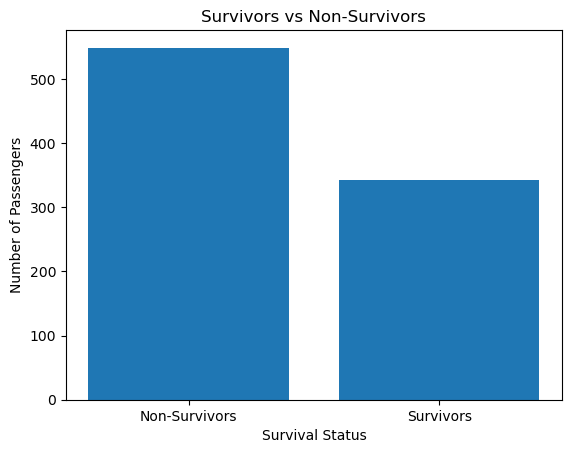

In [42]:
survival_counts = df['Survived'].value_counts()
plt.bar(['Non-Survivors', 'Survivors'], survival_counts)
plt.title("Survivors vs Non-Survivors")
plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")

3. Create a bar chart comparing survival counts by gender. 

Text(0, 0.5, 'Number of Survivors')

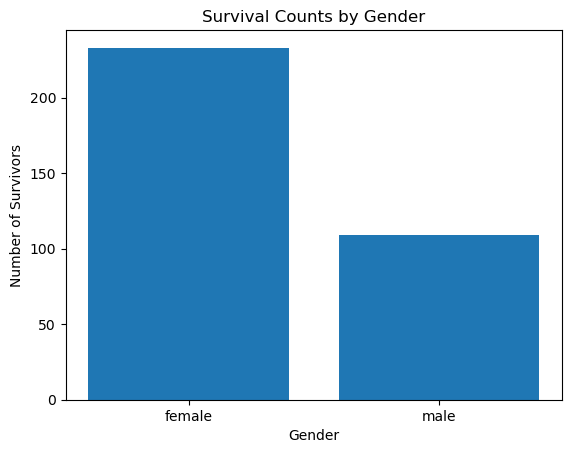

In [43]:
survival_gender = df.groupby('Sex')['Survived'].sum()

plt.bar(survival_gender.index, survival_gender.values)

plt.title("Survival Counts by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Survivors")

4. Give two meaningful observations from the plots.

Ans 4
1. Number of Female survivers are more than number of male survivers.
2. Survival rate was low as we can see that the no of non survivers is more than no of survivers